# PetroNova — full pipeline (VFM + PTA)

This notebook runs our whole solution from raw data to the final deliverables:

1. **Clean the raw data** (`src/prep.py`)
2. **Phase 1 – Virtual Flow Meter**: train the physics-hybrid model and predict daily oil / water / gas rates (`src/vfm.py`)
3. **Phase 2 – Pressure Transient Analysis**: analyse every shut-in, estimate permeability, skin and boundaries (`src/pta.py`)

All result files land in `outputs/`. Method details are in `METHODOLOGY.md`.

In [1]:
import sys, json, pickle
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import prep, vfm, pta
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

## 1. Clean the raw data
Removes sensor spikes and gaps, attaches choke positions, builds the daily table, the well-test training table and the list of shut-ins.

In [2]:
prep.main()

cleaning log: {'rows_raw': 3917073, 'exact_duplicates_dropped': 2513, 'conflicting_duplicates_merged': 0, 'sentinels_to_nan': 7410, 'spikes_removed': {'whp_psia': 108, 'whp_downstream_psia': 55, 'dh_pressure_psia': 105, 'dh_temperature_degf': 41, 'annulus_pressure_psia': 85, 'gas_lift_rate_mscfd': 54}, 'rows_clean': 3914560}
daily (2730, 17)  low-coverage days 8  fully shut days 5
tests (85, 70)  repaired water/gas/lift-sign: 1/10/2  still bad oil/water/gas: 0/0/0  tests overlapping a shut-in: 0
shut-ins:
 well_name          shut_start            shut_end  duration_hr  inside_hf_window
    GL-01 2025-04-15 08:00:00 2025-04-18 08:00:00        72.00              True
    GL-02 2025-03-08 14:23:00 2025-03-08 20:02:00         5.65              True
    GL-04 2025-06-03 08:00:00 2025-06-05 08:00:00        48.00              True
    GL-06 2025-07-22 03:11:00 2025-07-22 11:11:00         8.00              True
    GL-08 2025-08-19 09:00:00 2025-08-22 09:00:00        72.00              True
  

In [3]:
print(json.dumps(json.loads(Path('work/cleaning_log.json').read_text()), indent=1))

{
 "rows_raw": 3917073,
 "exact_duplicates_dropped": 2513,
 "conflicting_duplicates_merged": 0,
 "sentinels_to_nan": 7410,
 "spikes_removed": {
  "whp_psia": 108,
  "whp_downstream_psia": 55,
  "dh_pressure_psia": 105,
  "dh_temperature_degf": 41,
  "annulus_pressure_psia": 85,
  "gas_lift_rate_mscfd": 54
 },
 "rows_clean": 3914560
}


## 2. Phase 1 — Virtual Flow Meter
Trains the model, checks it against well tests, saves it (`outputs/vfm_model.pkl`) and writes daily predictions.

In [4]:
vfm.main()

drawdown per well (psi): {'GL-01': 271.0, 'GL-02': 508.0, 'GL-03': 390.0, 'GL-04': 1321.0, 'GL-05': 390.0, 'GL-06': 180.0, 'GL-07': 390.0, 'GL-08': 798.0, 'GL-09': 390.0, 'GL-10': 228.0}


MAPE % (lower is better)
 target                                                        oil_rate_stbd  water_rate_stbd  gas_rate_mscfd   mean
split                     model                                                                                    
A: leave-one-test-out     dummy: well average                          8.08             7.05            9.89   8.34
                          dummy: line between tests                    4.09             4.67            7.65   5.47
                          trend only (no sensors)                      4.55             4.67            7.61   5.61
                          v1: unconstrained ML (first model)           2.62             3.11            6.05   3.93
                          v2: physics-hybrid (FINAL)                   2.48             3.55            6.09   4.04
B: forward (last 2 tests) dummy: well average                         15.04             9.82           15.49  13.45
                          dummy: line between 


physics diagnostics: {
 "lambda_learned_from_tests": 0.8644780638865514,
 "liftcut_oil_change_pct_v1": {
  "GL-01": 14.8,
  "GL-02": 10.6,
  "GL-03": 32.2,
  "GL-04": 68.0,
  "GL-05": 38.8,
  "GL-06": 1.4,
  "GL-07": 10.0,
  "GL-08": 5.9,
  "GL-09": 35.5,
  "GL-10": 10.9
 },
 "liftcut_oil_change_pct_v2": {
  "GL-01": -9.0,
  "GL-02": -5.1,
  "GL-03": -17.2,
  "GL-04": -6.7,
  "GL-05": -18.7,
  "GL-06": -11.1,
  "GL-07": -3.7,
  "GL-08": -3.1,
  "GL-09": -12.3,
  "GL-10": -3.6
 },
 "normal_days_vs_test_pct_v1": -0.28683447598806255,
 "normal_days_vs_test_pct_v2": -2.184826717275179,
 "oil_coefficients_per_std": {
  "choke_opening_pct": 0.0245,
  "dh_pressure_psia_slow": 0.1237,
  "dh_temperature_degf_slow": 0.2006
 }
}



normal days next to a test vs measured test rate (median offset, %): {'oil_rate_stbd': -2.2, 'water_rate_stbd': -2.7, 'gas_rate_mscfd': -2.5}

daily predictions: (2730, 10) NaN cells: 0


wrote C:\Users\thsem\OneDrive\Desktop\Socar Hackathon\outputs\VFM_daily_predictions.xlsx


### Validation — MAPE % (lower is better)

In [5]:
val = pd.read_csv('work/vfm_validation.csv')
piv = val.pivot_table(index=['split', 'model'], columns='target', values='MAPE_%', sort=False).round(2)
piv['mean'] = piv.mean(axis=1).round(2)
piv

target                                                        oil_rate_stbd  water_rate_stbd  gas_rate_mscfd   mean
split                     model                                                                                    
A: leave-one-test-out     dummy: well average                          8.08             7.05            9.89   8.34
                          dummy: line between tests                    4.09             4.67            7.65   5.47
                          trend only (no sensors)                      4.55             4.67            7.61   5.61
                          v1: unconstrained ML (first model)           2.62             3.11            6.05   3.93
                          v2: physics-hybrid (FINAL)                   2.48             3.55            6.09   4.04
B: forward (last 2 tests) dummy: well average                         15.04             9.82           15.49  13.45
                          dummy: line between tests                    8.09             7.46           10.76   8.77
                          trend only (no sensors)                      7.14             6.38           10.22   7.91
                          v1: unconstrained ML (first model)           2.59             3.48            5.16   3.74
                          v2: physics-hybrid (FINAL)                   2.84             4.00            5.43   4.09

### Physics checks

In [6]:
pd.read_excel('outputs/VFM_daily_predictions.xlsx', sheet_name='physics_checks')

,physics check,value
0,lambda learned from tests (physics says 1.0),0.864
1,"normal days vs tests, v1 (%)",-0.29
2,"normal days vs tests, v2 FINAL (%)",-2.18
3,"14-Jun lift-gas outage, oil change GL-01: v1 /...",+14.8 / -9.0
4,"14-Jun lift-gas outage, oil change GL-02: v1 /...",+10.6 / -5.1
5,"14-Jun lift-gas outage, oil change GL-03: v1 /...",+32.2 / -17.2
6,"14-Jun lift-gas outage, oil change GL-04: v1 /...",+68.0 / -6.7
7,"14-Jun lift-gas outage, oil change GL-05: v1 /...",+38.8 / -18.7
8,"14-Jun lift-gas outage, oil change GL-06: v1 /...",+1.4 / -11.1
9,"14-Jun lift-gas outage, oil change GL-07: v1 /...",+10.0 / -3.7


### Daily predictions (first rows)

In [7]:
pred = pd.read_excel('outputs/VFM_daily_predictions.xlsx', sheet_name='predictions')
print(pred.shape)
pred.head(10)

(2730, 5)


,date,well_name,oil_rate_stbd,water_rate_stbd,gas_rate_mscfd
0,2025-01-01,GL-01,1154.3,791.1,315.7
1,2025-01-02,GL-01,1159.1,790.8,317.0
2,2025-01-03,GL-01,1184.6,815.8,323.5
3,2025-01-04,GL-01,1174.7,801.6,321.0
4,2025-01-05,GL-01,1165.7,794.5,318.7
5,2025-01-06,GL-01,1152.1,794.5,315.2
6,2025-01-07,GL-01,1153.4,794.3,315.5
7,2025-01-08,GL-01,1135.6,791.1,310.7
8,2025-01-09,GL-01,1121.1,790.0,306.8
9,2025-01-10,GL-01,1122.8,793.4,307.2


### The saved model loads back from the .pkl file

In [8]:
with open('outputs/vfm_model.pkl', 'rb') as f:
    model = pickle.load(f)
type(model)

vfm.RatioVFM

## 3. Phase 2 — Pressure Transient Analysis
For every shut-in: Horner and Bourdet-derivative analysis → permeability, skin, ΔP skin, radius of investigation and a written interpretation.

In [9]:
pta.main()

well_name       shut_in_start  duration_hr  horner_slope_psi_cycle  permeability_md  skin  dp_skin_psi  q_oil_vfm_stbd  radial_window_start_hr  radial_window_end_hr  derivative_flatness_cv  m_from_derivative quality         late_time_behaviour
    GL-01 2025-04-15 08:00:00        72.00                   23.27           107.79  5.72       115.66         1009.43                    1.96                  6.19                    0.06              23.28       B boundary / pressure support
    GL-02 2025-03-08 14:23:00         5.65                   52.68            58.25 -0.56       -25.59         1321.66                    1.66                  5.26                    0.01              52.65       A           still radial flow
    GL-04 2025-06-03 08:00:00        48.00                  144.95            55.49 -1.26      -158.26          807.80                   14.02                 44.35                    0.02             144.76       A           still radial flow
    GL-06 2025-07-22 03:

### PTA results

In [10]:
pd.read_excel('outputs/PTA_results.xlsx', sheet_name='results')

,well_name,shut_in_start,duration_hr,horner_slope_psi_cycle,permeability_md,skin,dp_skin_psi
0,GL-01,2025-04-15 08:00:00,72.00,23.271,107.795,5.719,115.658
1,GL-02,2025-03-08 14:23:00,5.65,52.678,58.249,-0.559,-25.591
2,GL-04,2025-06-03 08:00:00,48.00,144.951,55.491,-1.256,-158.260
3,GL-06,2025-07-22 03:11:00,8.00,15.044,296.089,1.948,25.469
4,GL-08,2025-08-19 09:00:00,72.00,93.485,43.069,-1.671,-135.750
5,GL-10,2025-05-27 21:04:00,9.00,28.908,181.241,2.001,50.262


In [11]:
det = pd.read_excel('outputs/PTA_results.xlsx', sheet_name='details')
cols = [c for c in ['well_name', 'shut_in_start', 'quality', 'late_time_behaviour', 'interpretation'] if c in det.columns]
with pd.option_context('display.max_colwidth', None):
    display(det[cols])

,well_name,shut_in_start,quality,late_time_behaviour,interpretation
0,GL-01,2025-04-15 08:00:00,B,boundary / pressure support,Damaged well (skin +5.7): only 68% of the drawdown drives flow; stimulation candidate. Moderate permeability. Late-time derivative drops: boundary or pressure support reached once the test had investigated about 668 ft (limited drainage area); average reservoir pressure at gauge is about 3512 psia.
1,GL-02,2025-03-08 14:23:00,A,still radial flow,Near-wellbore condition close to undamaged (skin -0.6). Moderate permeability.
2,GL-04,2025-06-03 08:00:00,A,still radial flow,Stimulated / fractured near the well (skin -1.3): flows better than an undamaged well. Moderate permeability.
3,GL-06,2025-07-22 03:11:00,A,still radial flow,Mild damage (skin +1.9). High permeability.
4,GL-08,2025-08-19 09:00:00,A,still radial flow,Stimulated / fractured near the well (skin -1.7): flows better than an undamaged well. Low-moderate permeability.
5,GL-10,2025-05-27 21:04:00,B,boundary / pressure support,Mild damage (skin +2.0). High permeability. Late-time derivative drops: boundary or pressure support reached once the test had investigated about 492 ft (limited drainage area); average reservoir pressure at gauge is about 3914 psia.


### PTA plots (also saved in `outputs/pta_plots/`)

GL-01_20250415_0800.png


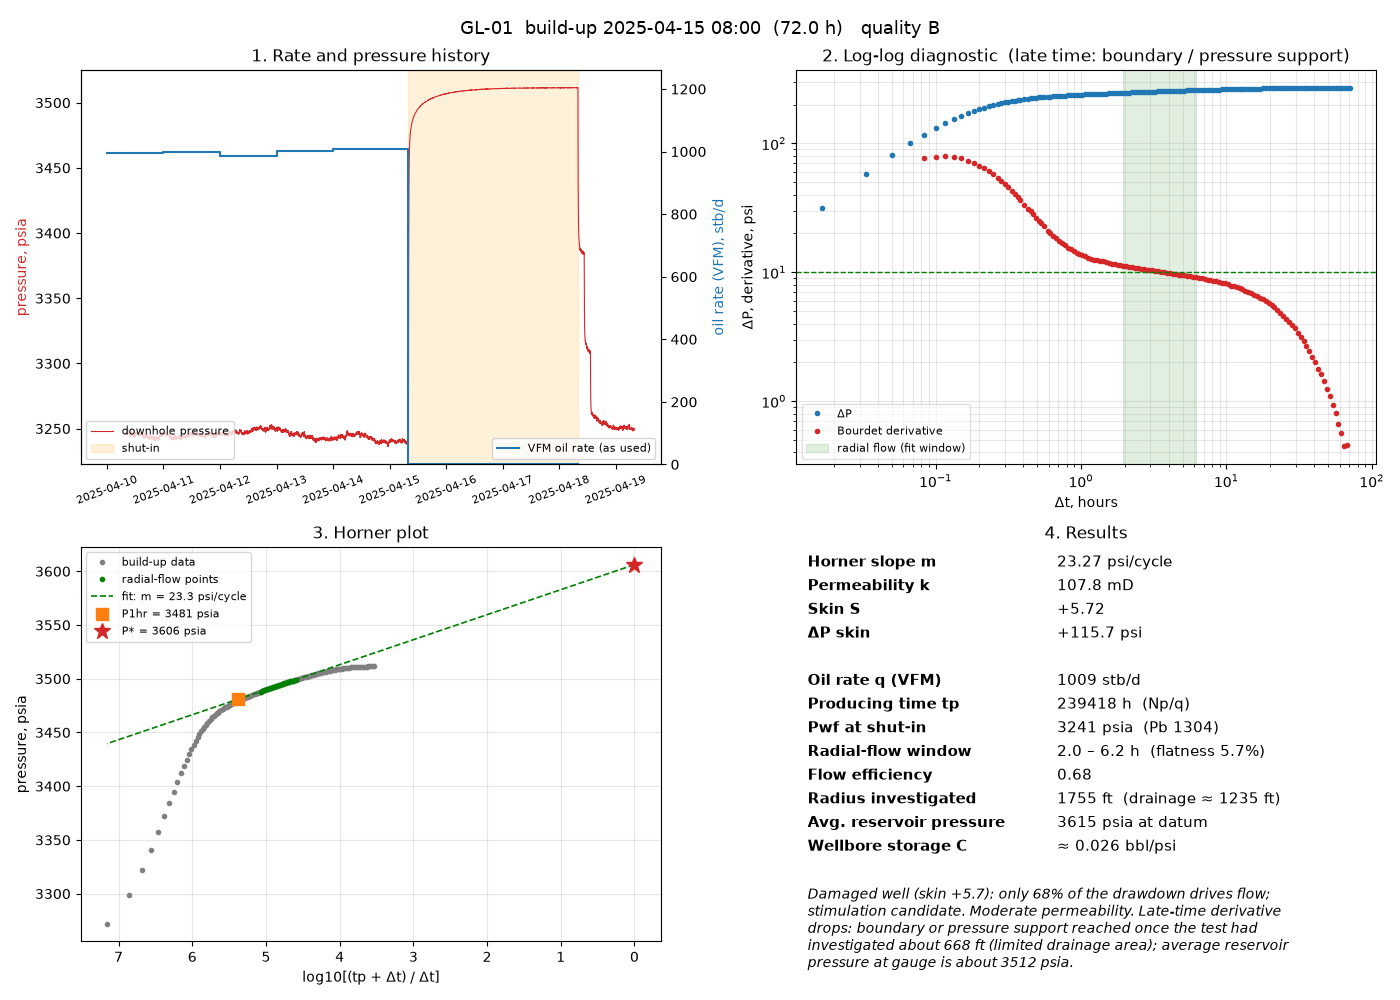

GL-02_20250308_1423.png


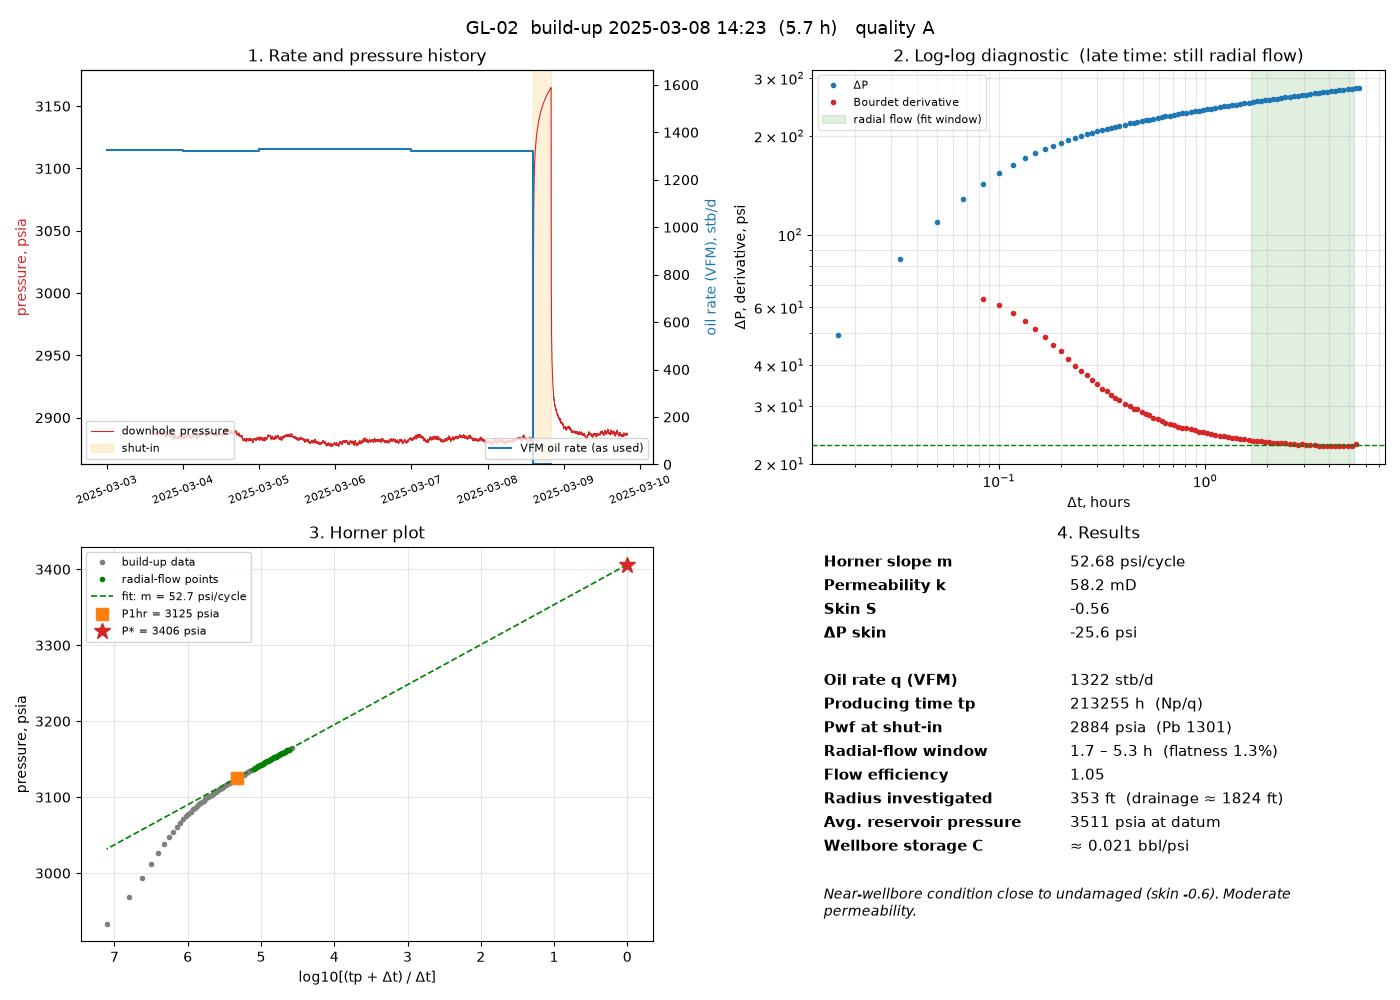

GL-04_20250603_0800.png


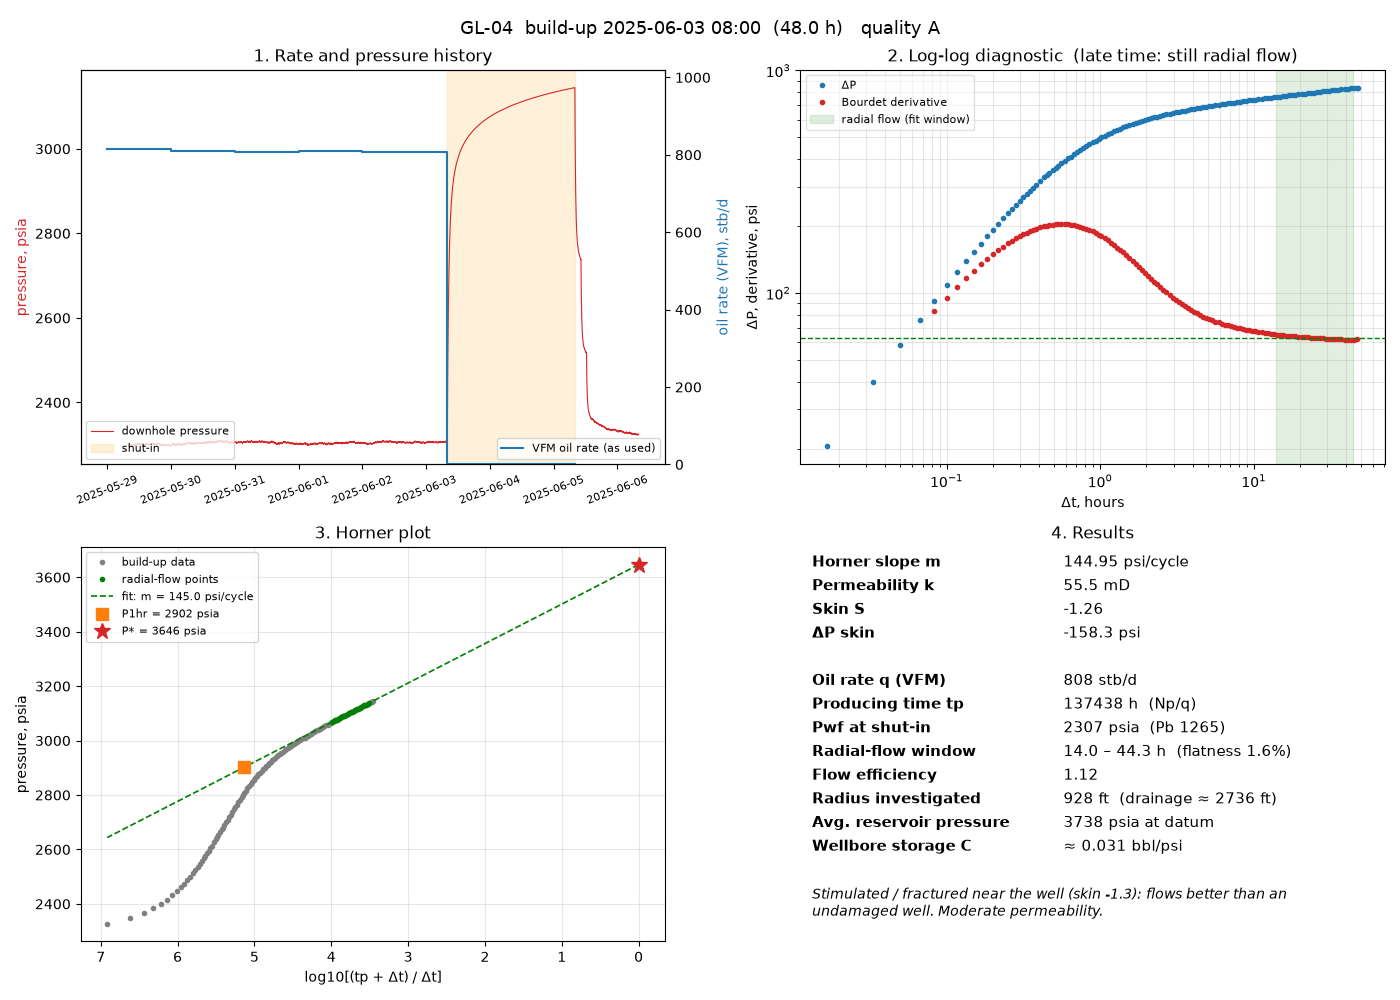

GL-06_20250722_0311.png


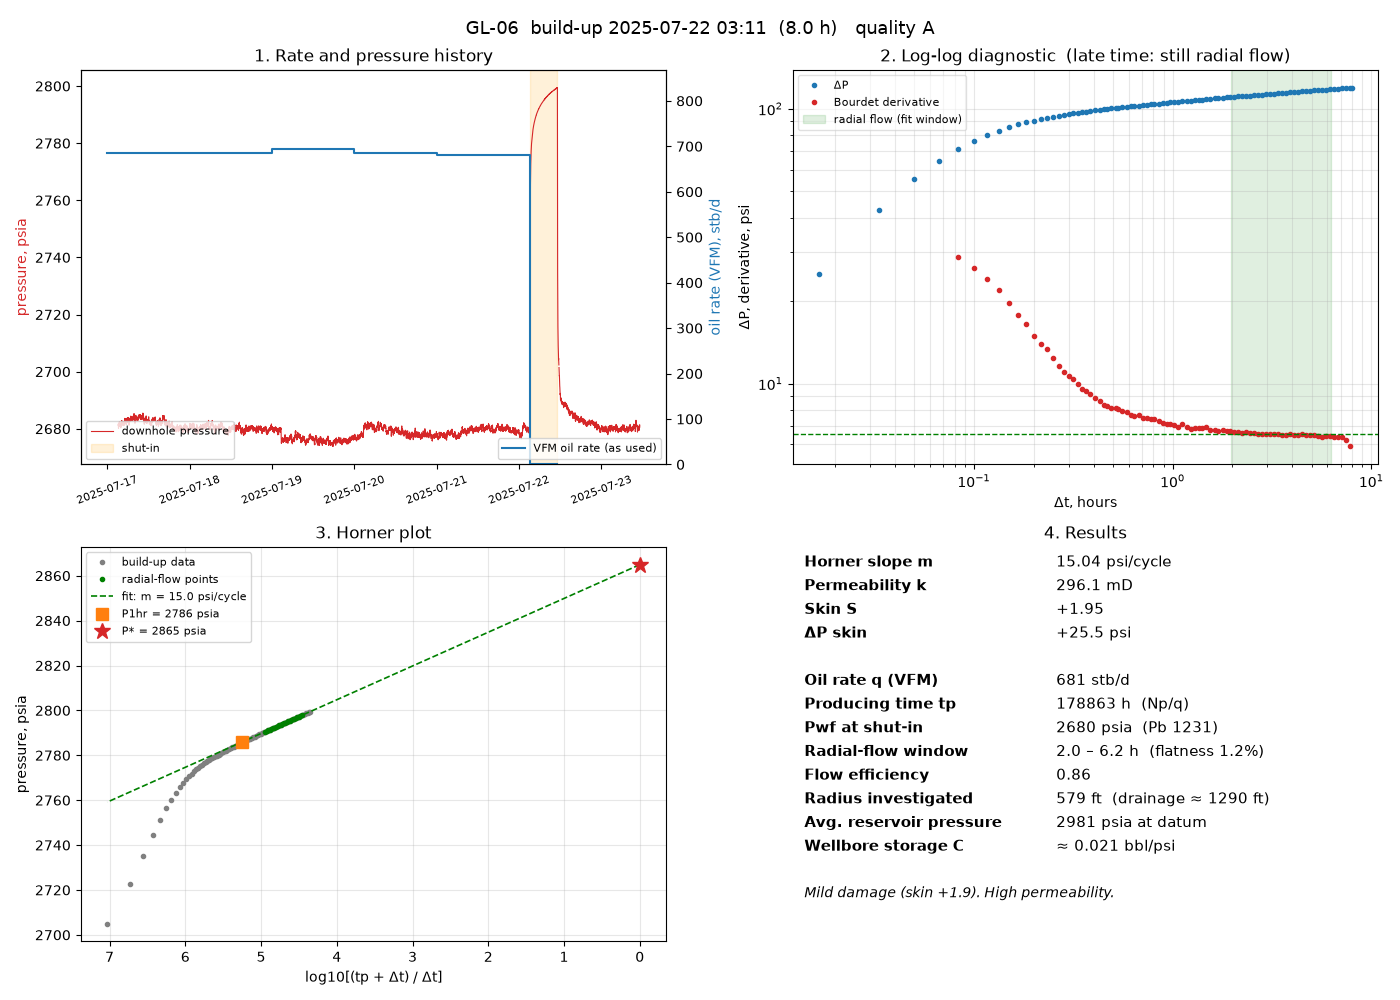

GL-08_20250819_0900.png


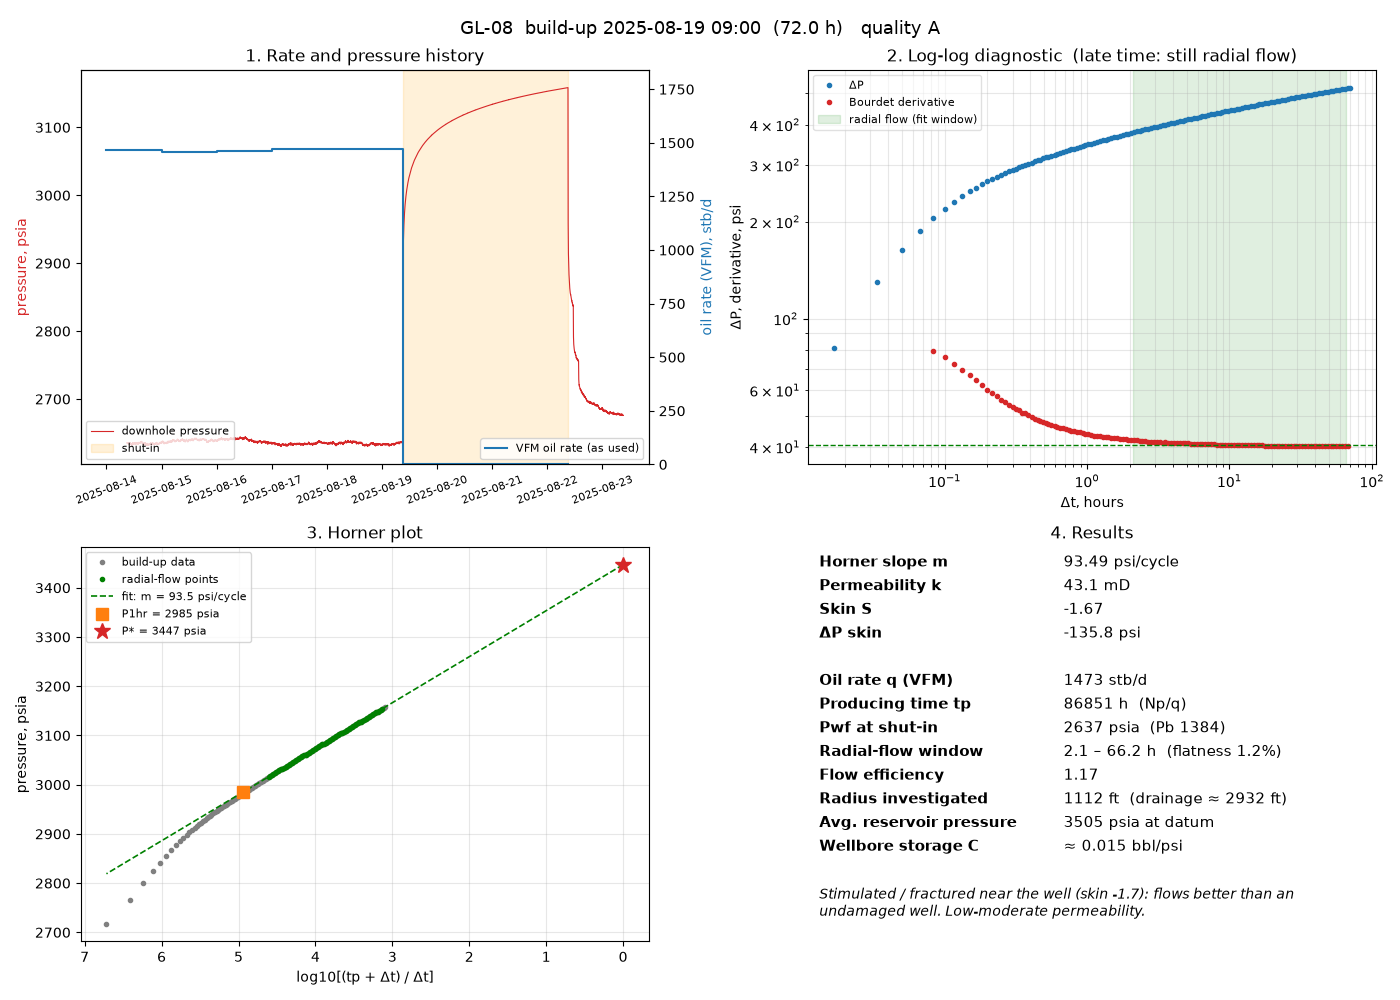

GL-10_20250527_2104.png


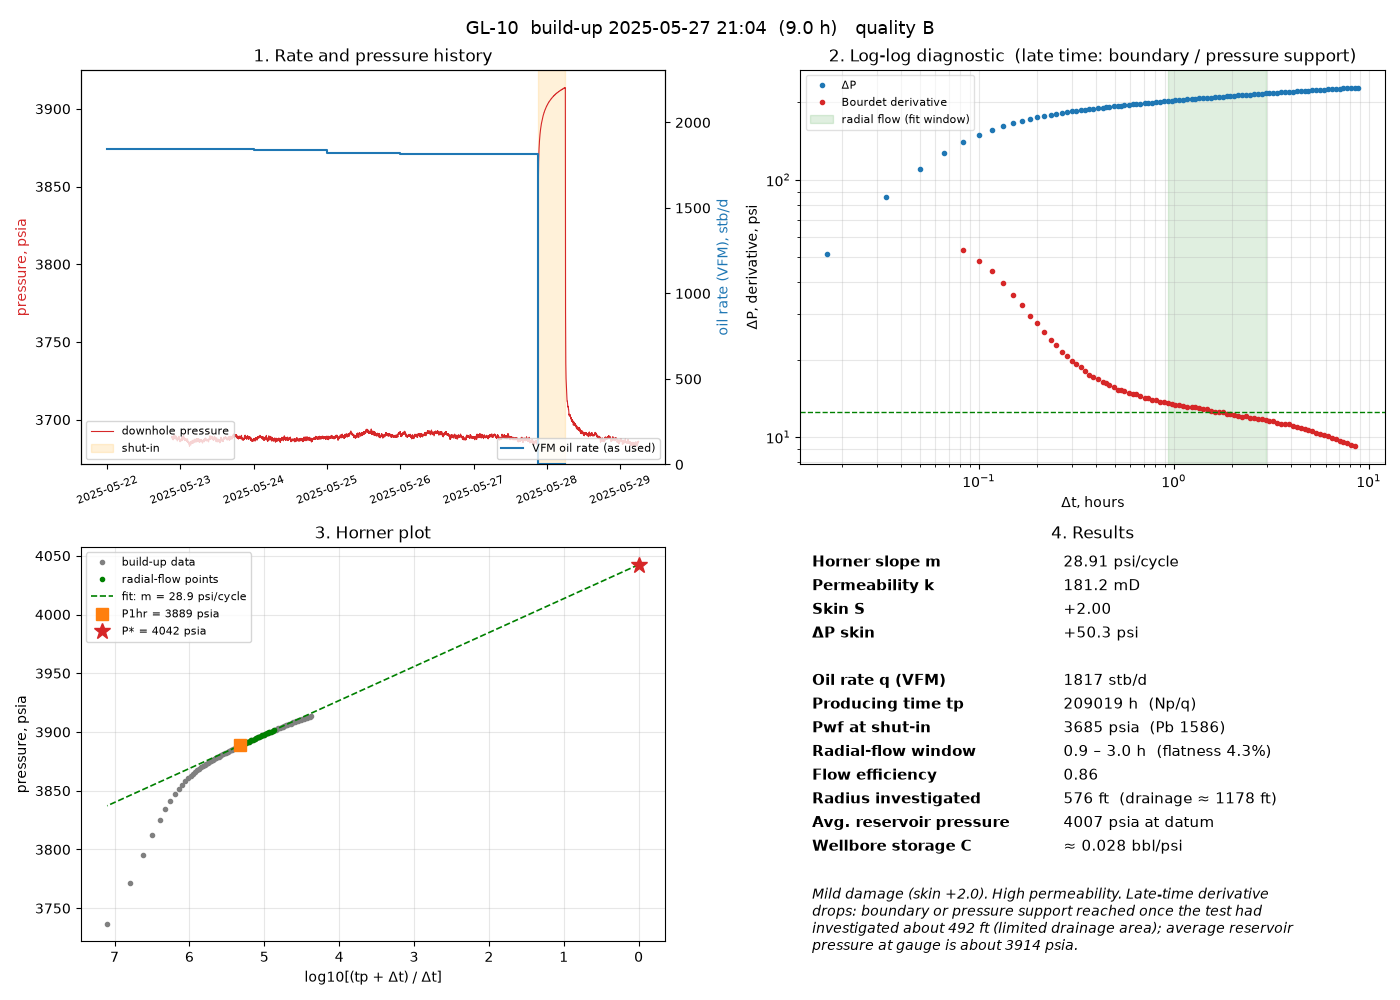

In [12]:
for png in sorted(Path('outputs/pta_plots').glob('*.png')):
    print(png.name)
    display(Image(filename=str(png), width=900))

## Deliverables produced
- `outputs/VFM_submission.csv`, `outputs/VFM_daily_predictions.xlsx` — Phase 1 results
- `outputs/PTA_results.xlsx` — Phase 2 results
- `outputs/vfm_model.pkl` — trained model
- `outputs/pta_plots/` — PTA plots